In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('credit_risk_dataset.csv')

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [5]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [6]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

C:\Users\bjkef\AppData\Local\Temp\ipykernel_24280\1933667895.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=ax, palette='Blues_r', edgecolor='black')
C:\Users\bjkef\AppData\Local\Temp\ipykernel_24280\1933667895.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=ax, palette='Blues_r', edgecolor='black')
C:\Users\bjkef\AppData\Local\Temp\ipykernel_24280\1933667895.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=ax, palette='Blues_r', edgecolor='black')
C:\Users\bjkef\A

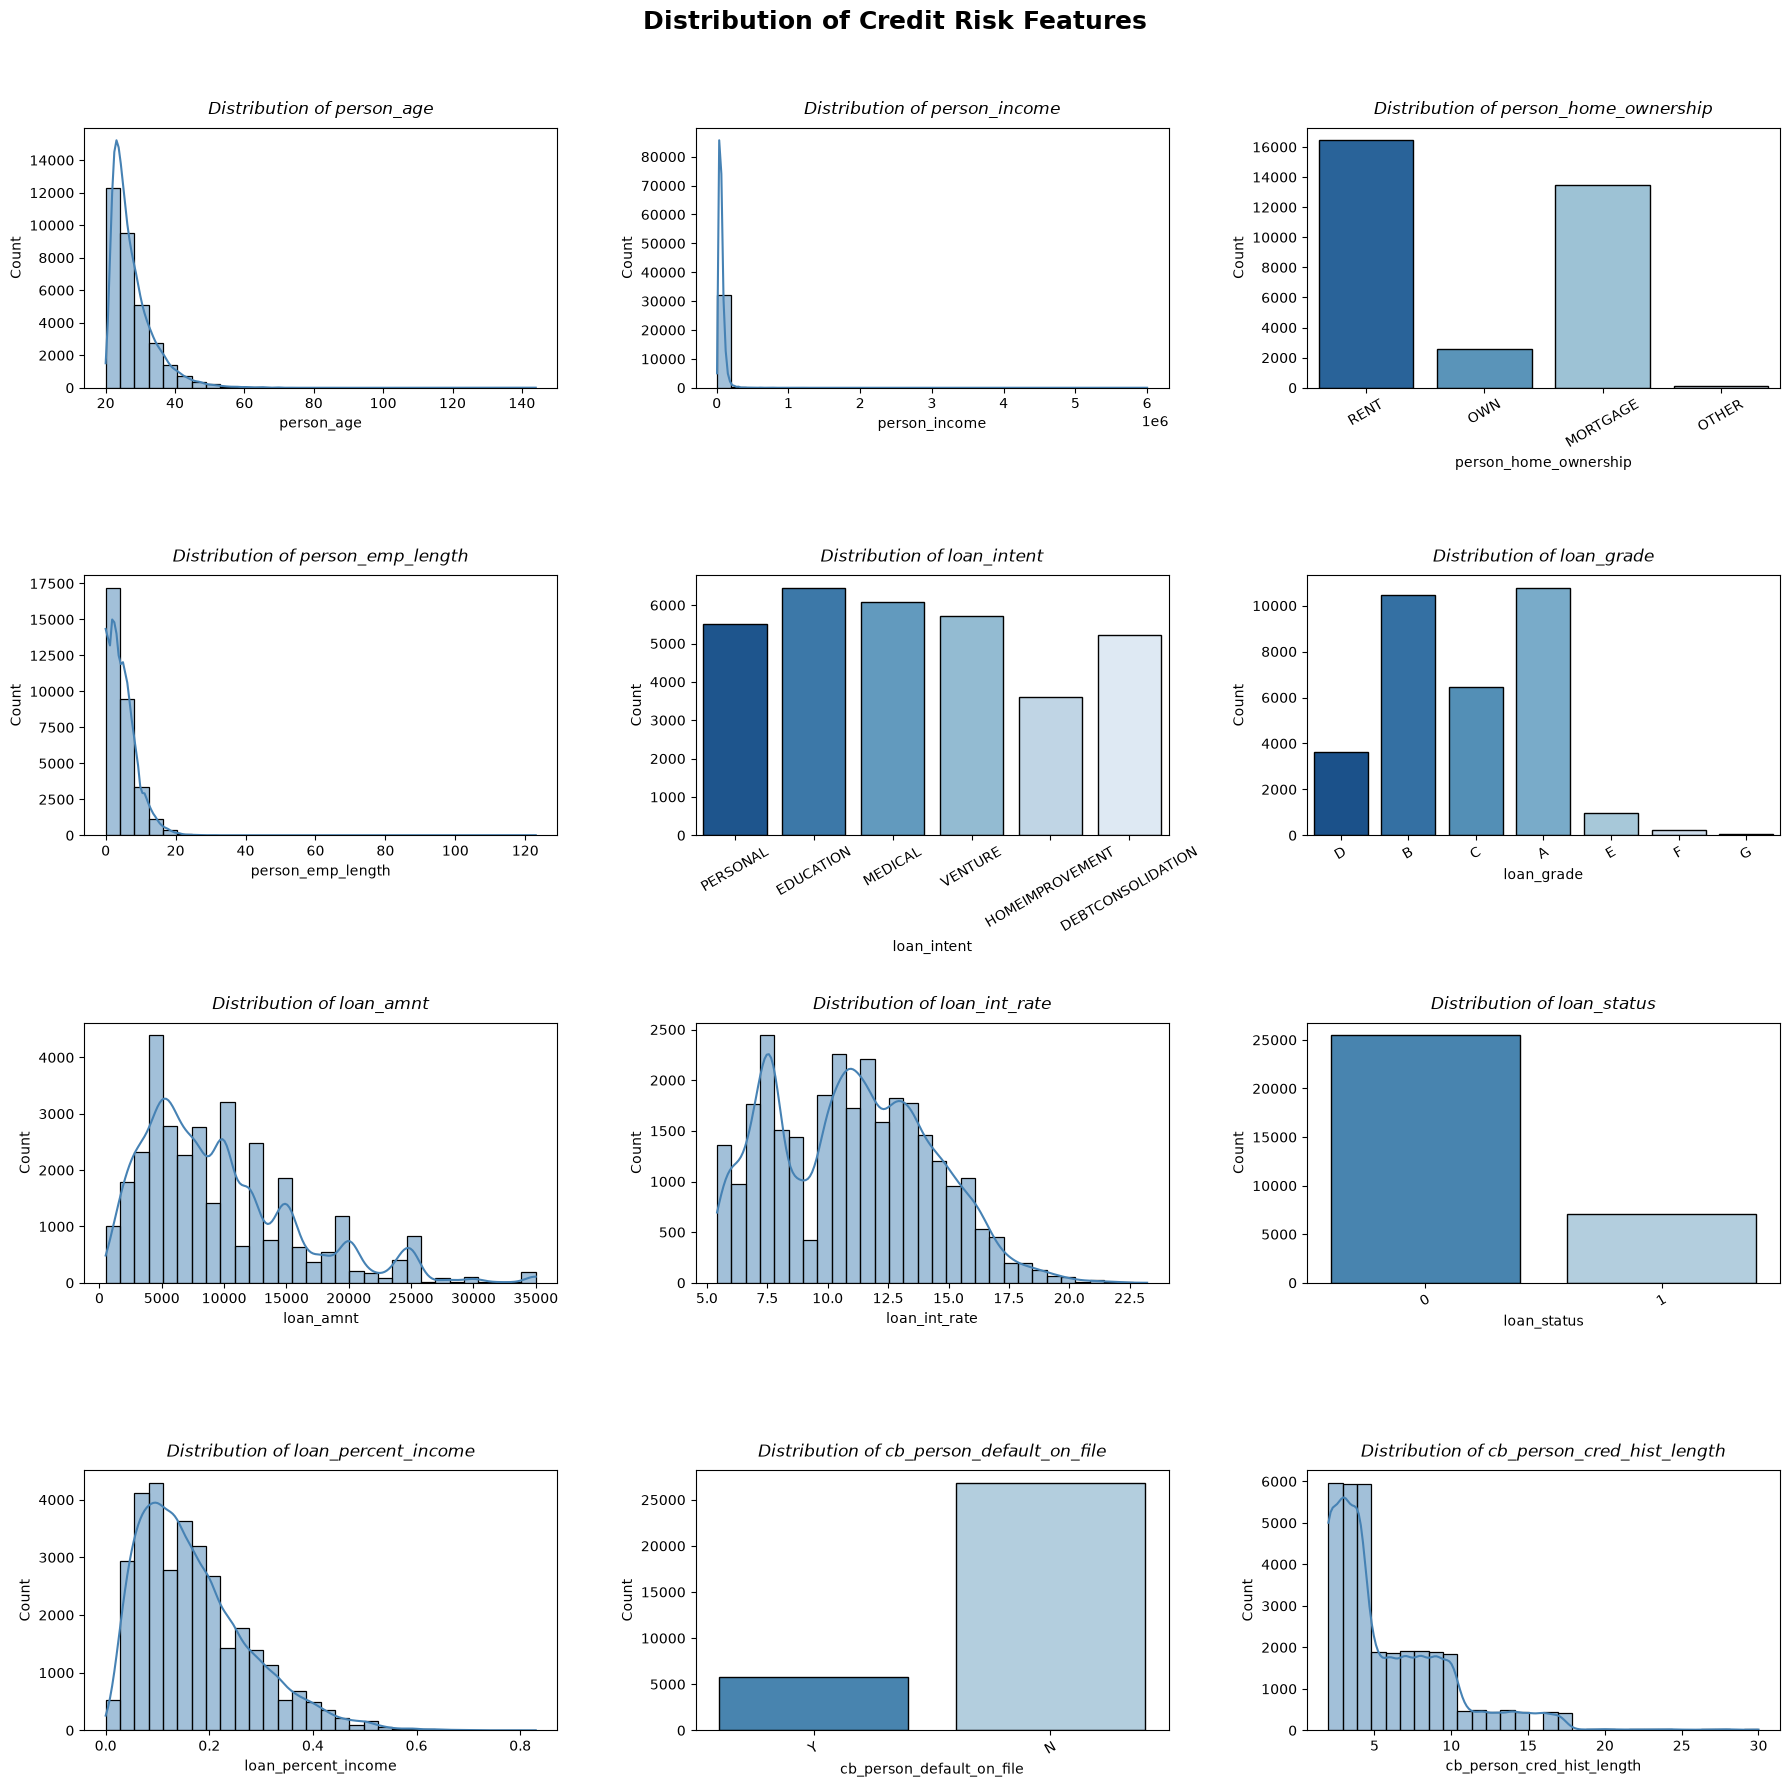

In [7]:
# 1. Dikey boyutu (12 -> 18) artırdık ki satırlar birbirine girmesin
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 18))
fig.suptitle("Distribution of Credit Risk Features", fontsize=18, fontweight='bold', y=0.99)

# axes.flatten() ile row = i // 3 ve col_idx = i % 3 hesabına gerek kalmaz
axes = axes.flatten()

for i, col in enumerate(df.columns):
    ax = axes[i]
    
    # Eğer sütun Kategorik (object) veya İkili Hedef Değişken (loan_status) ise Countplot çiz
    if df[col].dtype == 'str' or col == 'loan_status':
        sns.countplot(data=df, x=col, ax=ax, palette='Blues_r', edgecolor='black')
        ax.tick_params(axis='x', rotation=30)  # Uzun yazıları 30 derece eğ
    
    # Eğer sütun Sayısal ise Histplot + KDE çiz
    else:
        sns.histplot(data=df, x=col, kde=True, ax=ax, bins=30, color='steelblue')
        
    ax.set_title(f'Distribution of {col}', fontsize=12, fontstyle='italic', pad=10)
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Count', fontsize=10)

# rect parametresi üstteki suptitle için boşluk bırakır, h_pad/w_pad grafikler arası mesafeyi açar
plt.tight_layout(rect=[0, 0, 1, 0.97], h_pad=3.0, w_pad=2.0)
plt.show()

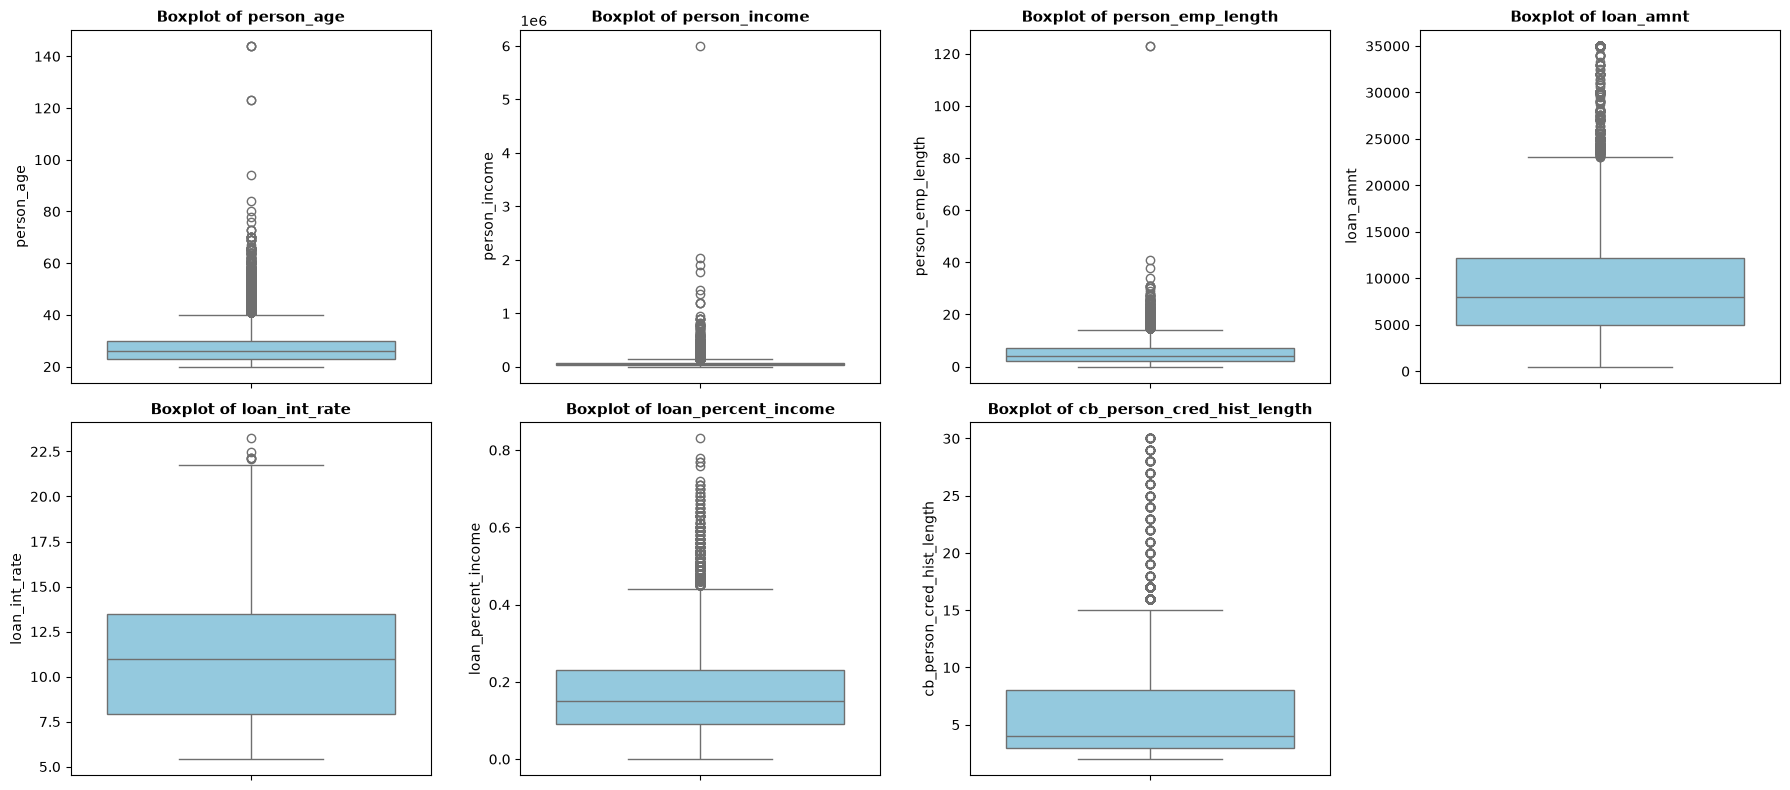

In [8]:
num_cols = ['person_age', 'person_income', 'person_emp_length', 
            'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, y=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot of {col}', fontsize=11, fontweight='bold')

fig.delaxes(axes[7]) # Boş kalan 8. kutuyu siler
plt.tight_layout()
plt.show()

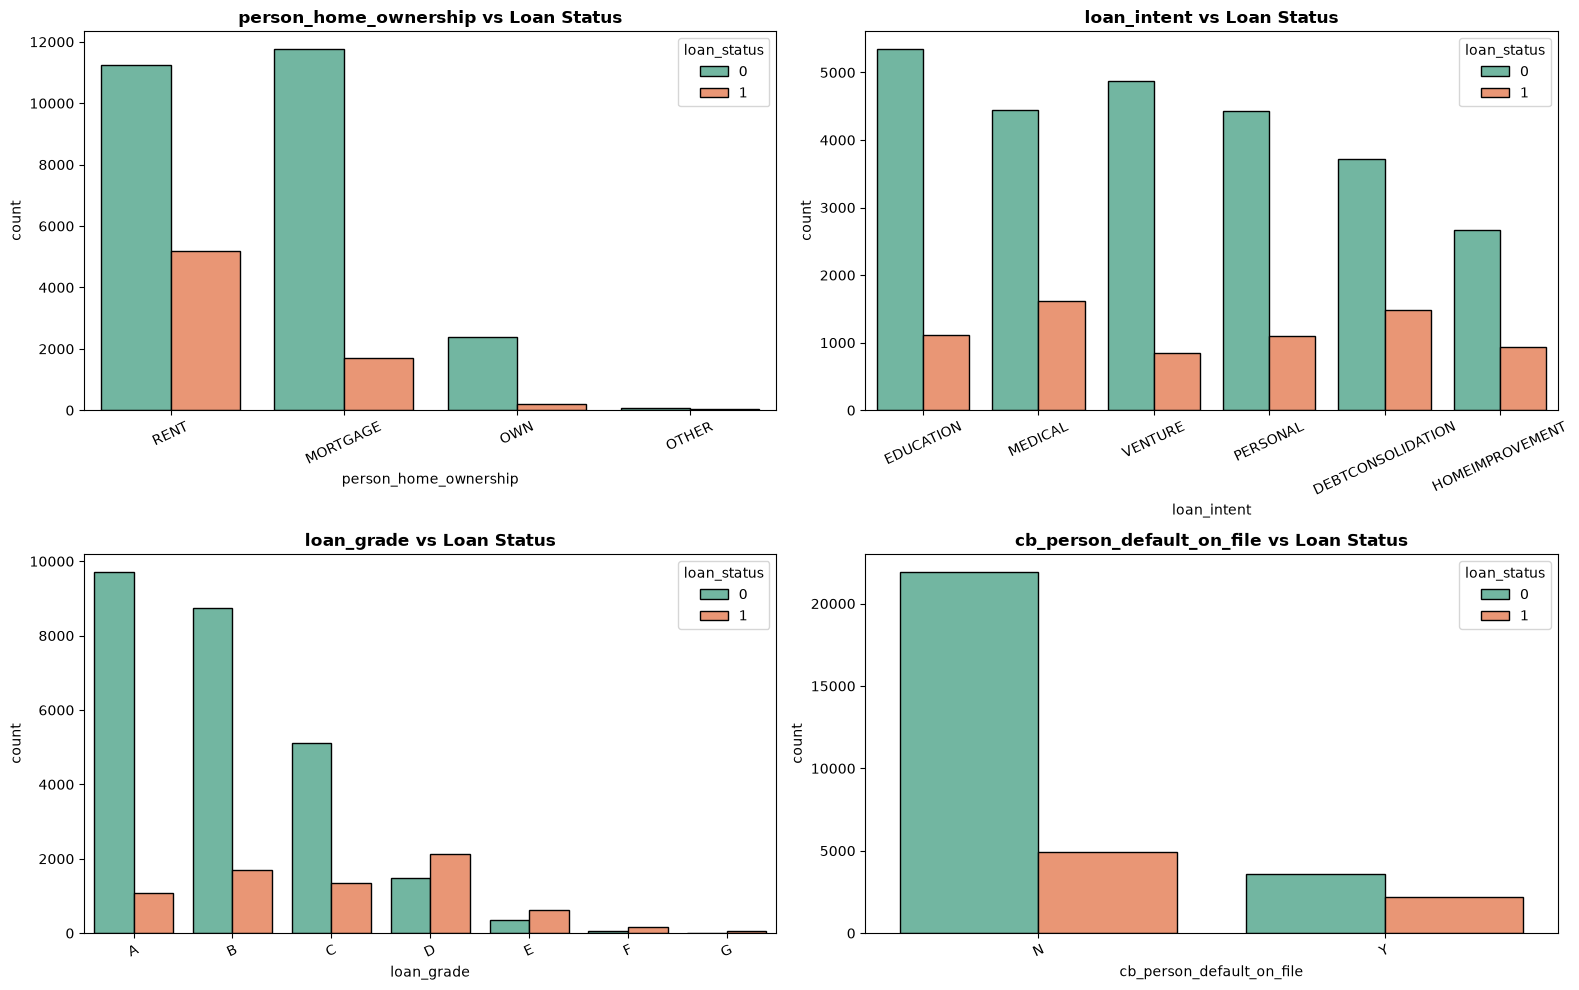

In [9]:
cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # order parametresi kategorileri sıklığa veya alfabetik sıraya göre dizer
    order = sorted(df[col].unique()) if col == 'loan_grade' else df[col].value_counts().index
    sns.countplot(data=df, x=col, hue='loan_status', order=order, ax=axes[i], palette='Set2', edgecolor='black')
    axes[i].set_title(f'{col} vs Loan Status', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

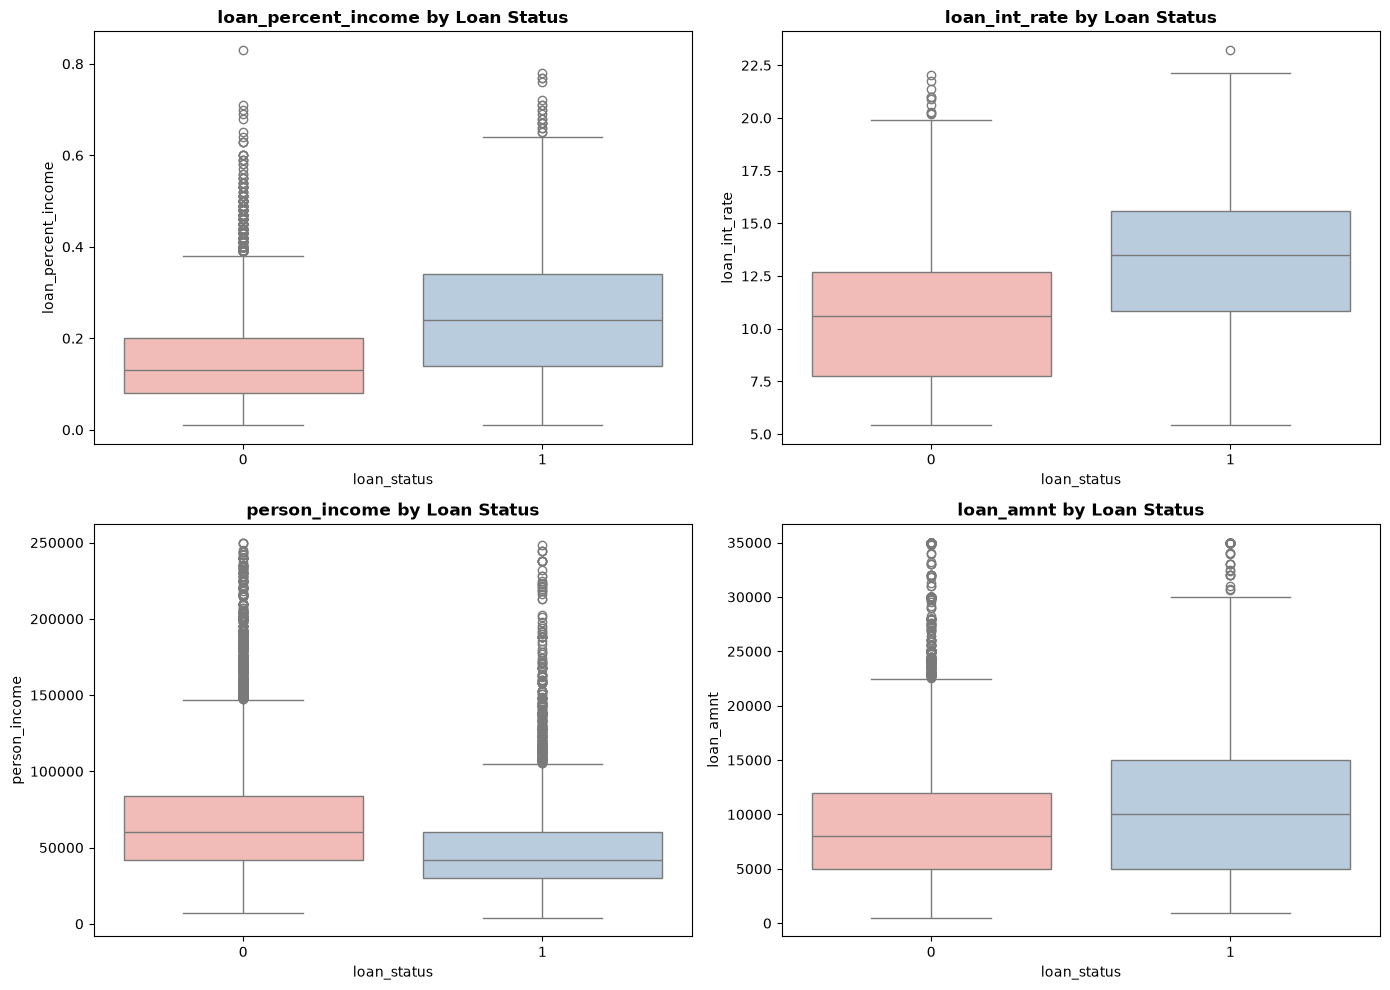

In [10]:
# Uç değerlerin grafiği bozmaması için görselleştirme sırasında yaş < 90 ve gelir < 250.000 filtresi uyguluyoruz
df_clean_viz = df[(df['person_age'] < 90) & (df['person_income'] < 250000) & (df['person_emp_length'] < 60)]

key_num_cols = ['loan_percent_income', 'loan_int_rate', 'person_income', 'loan_amnt']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(key_num_cols):
    sns.boxplot(data=df_clean_viz, x='loan_status', y=col, hue='loan_status', ax=axes[i], palette='Pastel1', legend=False)
    axes[i].set_title(f'{col} by Loan Status', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

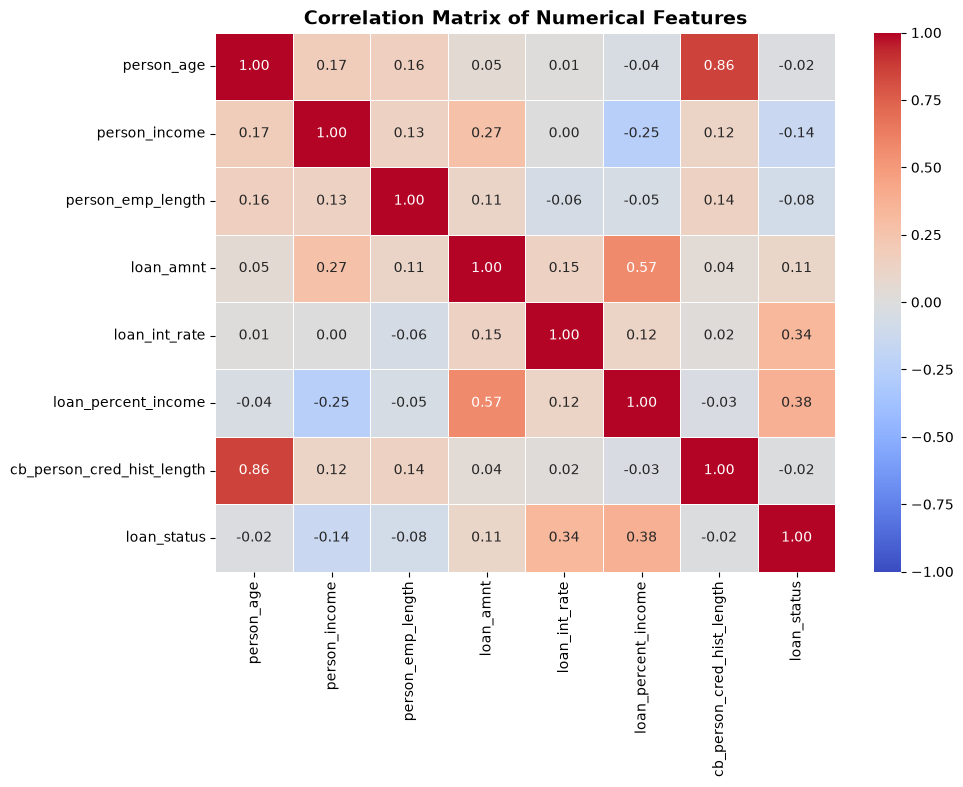

In [11]:
plt.figure(figsize=(10, 7))
corr_matrix = df[num_cols + ['loan_status']].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features", fontsize=14, fontweight='bold')
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer

# 1. Tekrarlayan (Duplicate) satırları temizle (~165 kopya satır var)
df = df.drop_duplicates().reset_index(drop=True)

# 2. Bağımsız değişkenler (X) ve Hedef değişken (y)
X = df.drop('loan_status', axis=1)
y = df['loan_status']

# 3. Train / Test Ayrımı (%80 Eğitim, %20 Test - Sınıf oranlarını koruyarak)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Orijinal Train boyutu: {X_train.shape}")
print(f"Test boyutu: {X_test.shape}")

Orijinal Train boyutu: (25932, 11)
Test boyutu: (6484, 11)


In [13]:
# Mantıklı eşik değerleri: Yaş <= 90, Çalışma Süresi <= 60 (veya boş olanlar), Gelir <= 1.5 Milyon
outlier_mask = (
    (X_train['person_age'] <= 90) & 
    ((X_train['person_emp_length'] <= 60) | (X_train['person_emp_length'].isna())) &
    (X_train['person_income'] <= 1500000)
)

# Maskeyi hem X_train hem de y_train'e uygula (indekslerin kaymaması için çok kritik!)
X_train = X_train[outlier_mask].reset_index(drop=True)
y_train = y_train[outlier_mask].reset_index(drop=True)

print(f"Outlier temizliği sonrası Train boyutu: {X_train.shape}")

Outlier temizliği sonrası Train boyutu: (25922, 11)


In [14]:
# Sütun gruplarını tanımlayalım
num_cols = [
    'person_age', 'person_income', 'person_emp_length', 
    'loan_amnt', 'loan_int_rate', 'loan_percent_income', 
    'cb_person_cred_hist_length'
]
ordinal_cols = ['loan_grade']
nominal_cols = ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']

# 1. Sayısal Değişken Pipeline'ı (Medyan ile doldurma + Yeo-Johnson Dönüşümü)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=True))
])

# 2. Sıralı Kategorik Pipeline'ı (A -> G sıralaması)
ordinal_pipeline = Pipeline(steps=[
    (' imputing', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[['A', 'B', 'C', 'D', 'E', 'F', 'G']]))
])

# 3. Nominal Kategorik Pipeline'ı (One-Hot Encoding)
nominal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# Tüm ön işleme adımlarını ColumnTransformer içinde birleştiriyoruz
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('nom', nominal_pipeline, nominal_cols)
])

# Ön işleme yapısını görselleştirip kontrol edelim
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [15]:
# Sadece X_train üzerinde fit_transform yapıyoruz, X_test üzerinde sadece transform!
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Dönüştürülmüş sütun isimlerini alalım
feature_names = preprocessor.get_feature_names_out()

# DataFrame olarak ilk 5 satıra bakalım
df_train_processed = pd.DataFrame(X_train_processed, columns=feature_names)
display(df_train_processed.head())
print(f"Eksik değer kaldı mı?: {df_train_processed.isna().sum().sum()}")

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,ord__loan_grade,nom__person_home_ownership_OTHER,nom__person_home_ownership_OWN,nom__person_home_ownership_RENT,nom__loan_intent_EDUCATION,nom__loan_intent_HOMEIMPROVEMENT,nom__loan_intent_MEDICAL,nom__loan_intent_PERSONAL,nom__loan_intent_VENTURE,nom__cb_person_default_on_file_Y
0,-0.933749,0.568553,-1.711675,-0.213026,-1.536062,-0.767725,-1.447863,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.286480,0.213318,1.102950,1.882550,0.593805,1.764996,-0.200878,2.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.893085,-0.061472,-1.711675,-0.425926,-1.536062,-0.491644,1.052834,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.206800,2.444101,1.553295,-0.425926,-1.301706,-1.761235,0.462135,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.590128,-0.031073,-1.711675,0.310950,1.249236,0.404371,1.052834,3.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


Eksik değer kaldı mı?: 0


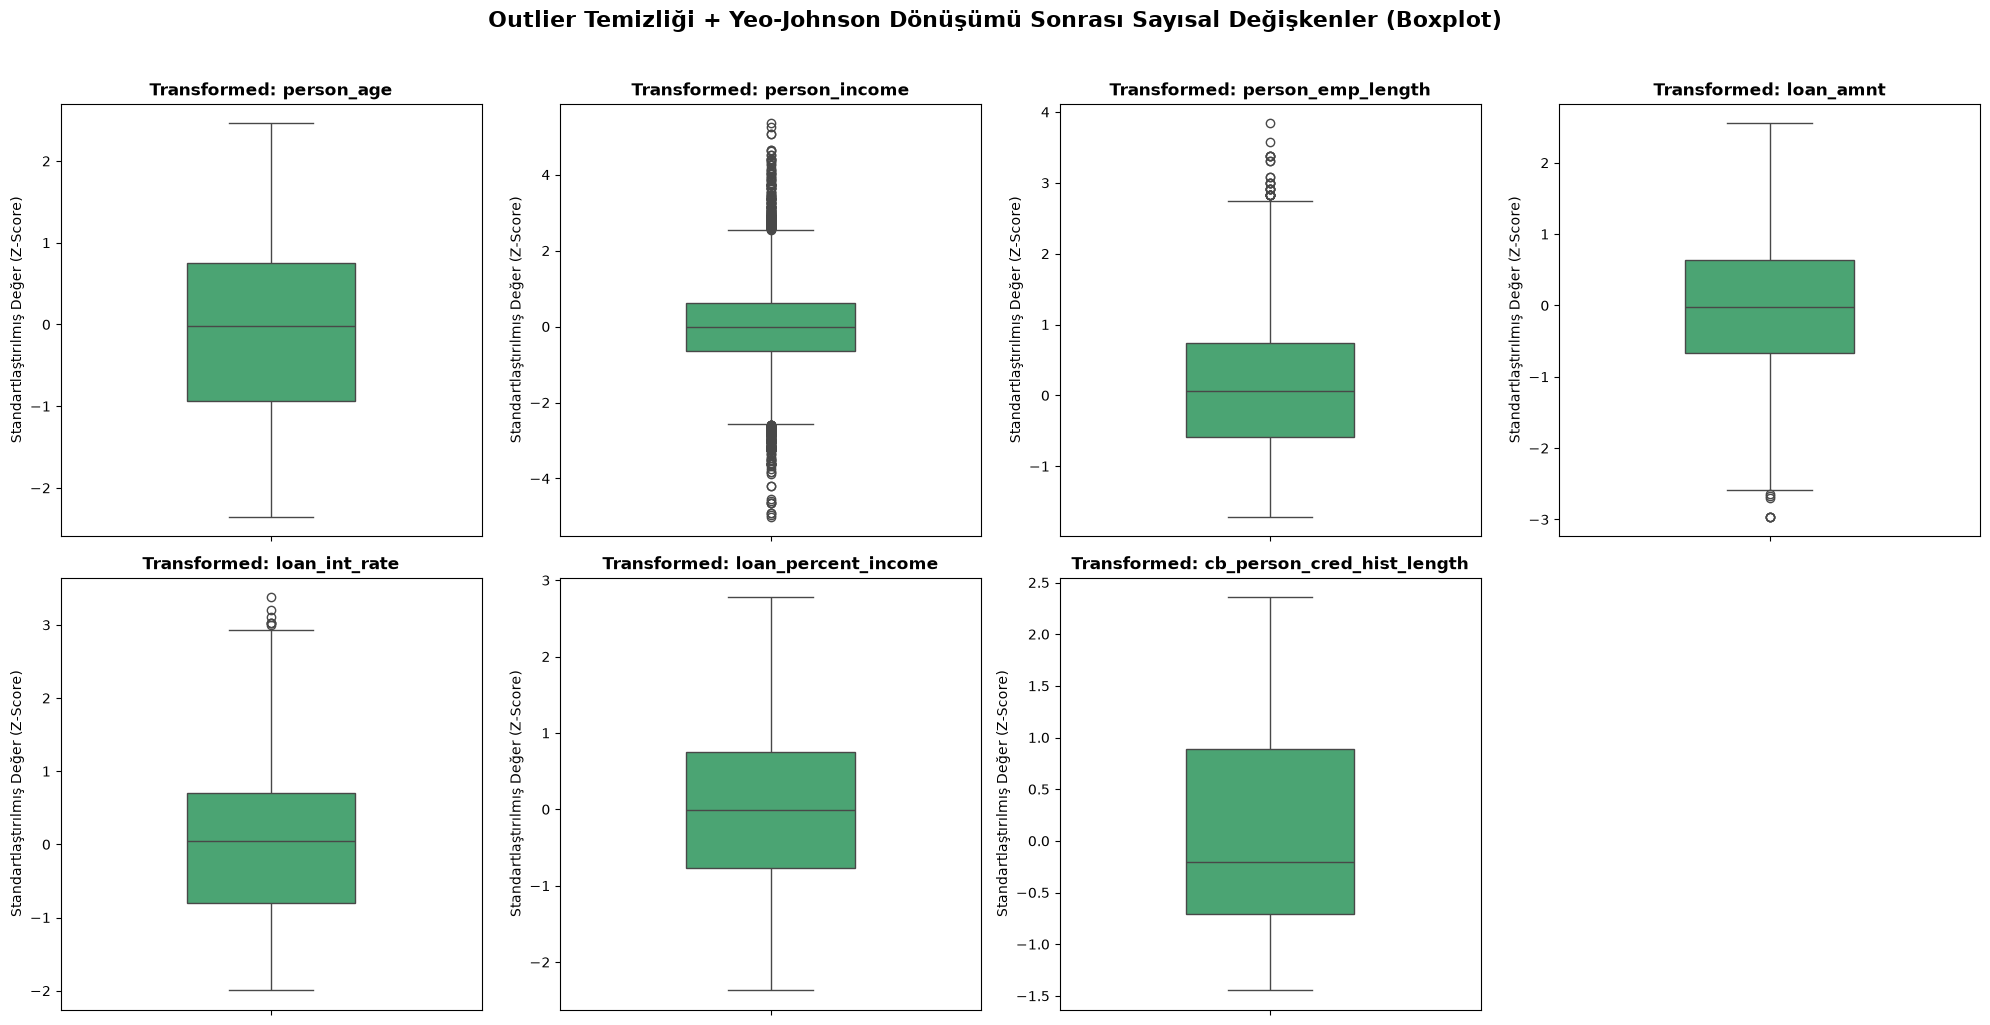

In [16]:
# Dönüştürülmüş verideki sayısal sütun isimleri ('num__' öneki alır)
processed_num_cols = [f'num__{col}' for col in num_cols]

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
fig.suptitle("Outlier Temizliği + Yeo-Johnson Dönüşümü Sonrası Sayısal Değişkenler (Boxplot)", fontsize=16, fontweight='bold', y=1.02)
axes = axes.flatten()

for i, col in enumerate(processed_num_cols):
    sns.boxplot(data=df_train_processed, y=col, ax=axes[i], color='mediumseagreen', width=0.4)
    # Başlıkta 'num__' kısmını temizleyerek gösterelim
    clean_name = col.replace('num__', '')
    axes[i].set_title(f'Transformed: {clean_name}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Standartlaştırılmış Değer (Z-Score)')

fig.delaxes(axes[7]) # 8. boş ekseni kaldır
plt.tight_layout()
plt.show()

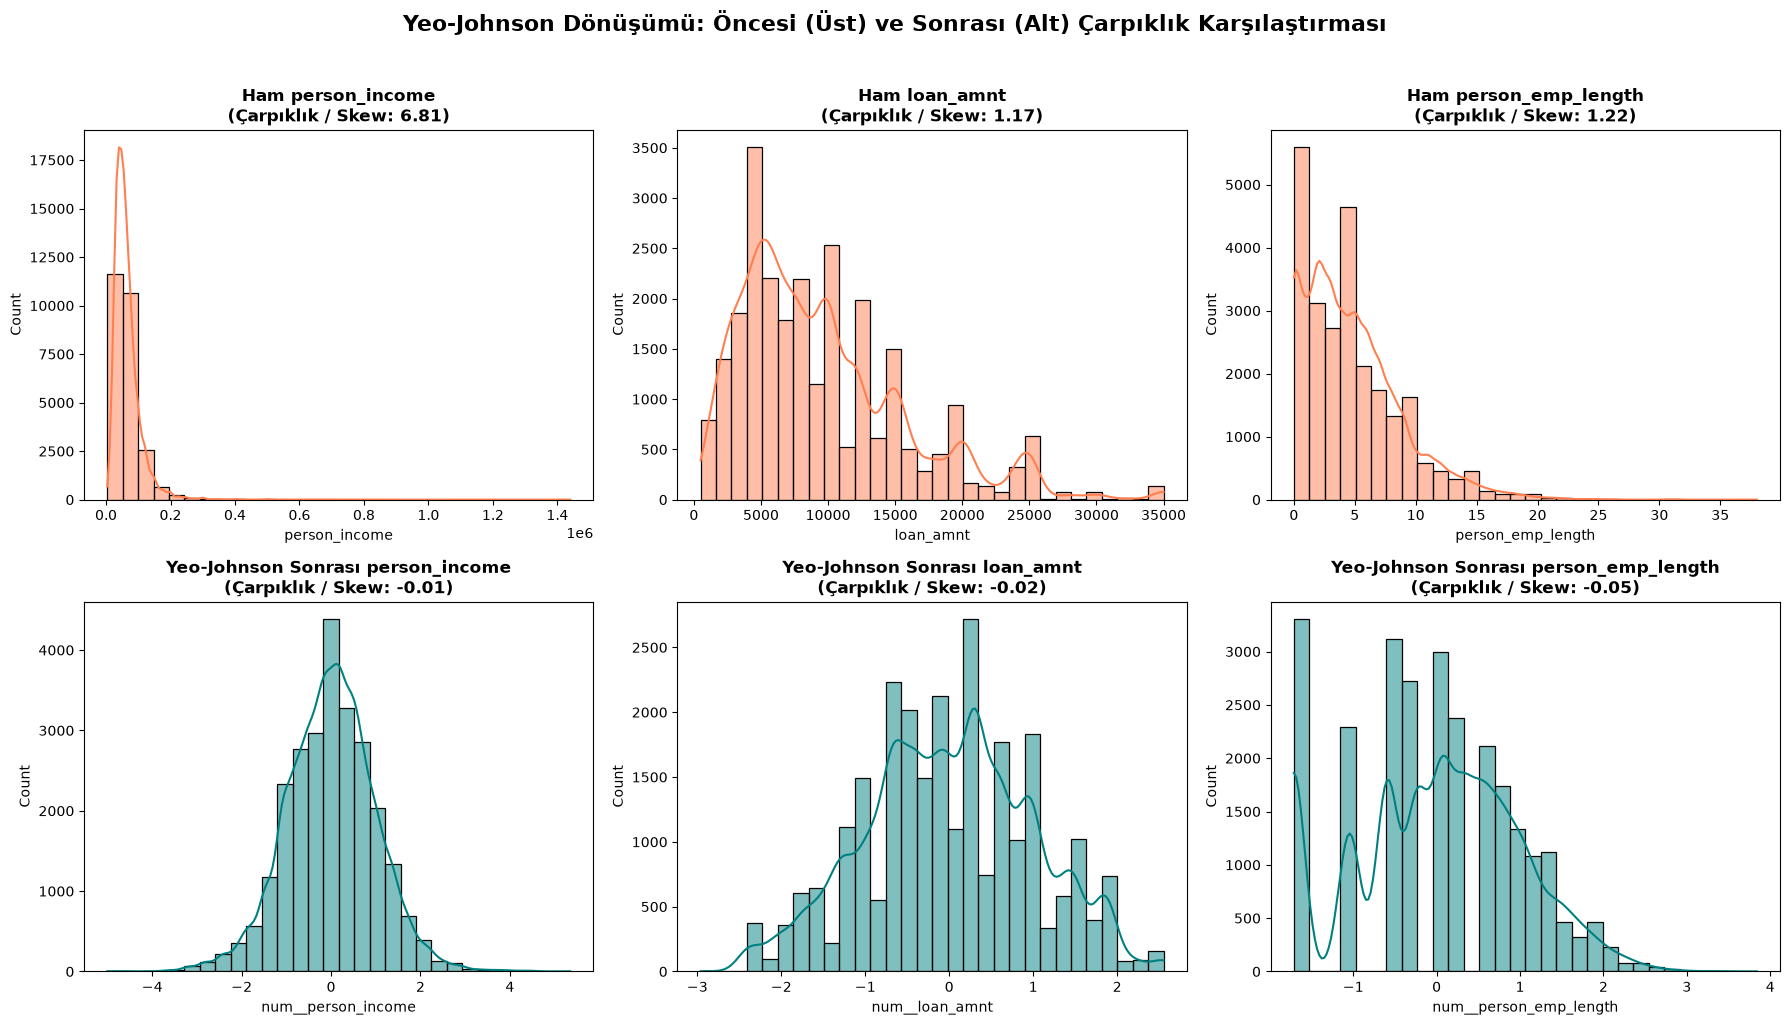

In [17]:
skewed_Vars = ['person_income', 'loan_amnt', 'person_emp_length']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
fig.suptitle("Yeo-Johnson Dönüşümü: Öncesi (Üst) ve Sonrası (Alt) Çarpıklık Karşılaştırması", fontsize=16, fontweight='bold', y=1.02)

for i, col in enumerate(skewed_Vars):
    # ÜST SATIR: Outlier temizlenmiş ama dönüştürülmemiş X_train
    skew_before = X_train[col].skew()
    sns.histplot(X_train[col].dropna(), kde=True, ax=axes[0, i], color='coral', bins=30)
    axes[0, i].set_title(f'Ham {col}\n(Çarpıklık / Skew: {skew_before:.2f})', fontsize=12, fontweight='bold')
    
    # ALT SATIR: Impute edilmiş + Yeo-Johnson uygulanmış df_train_processed
    proc_col = f'num__{col}'
    skew_after = df_train_processed[proc_col].skew()
    sns.histplot(df_train_processed[proc_col], kde=True, ax=axes[1, i], color='teal', bins=30)
    axes[1, i].set_title(f'Yeo-Johnson Sonrası {col}\n(Çarpıklık / Skew: {skew_after:.2f})', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

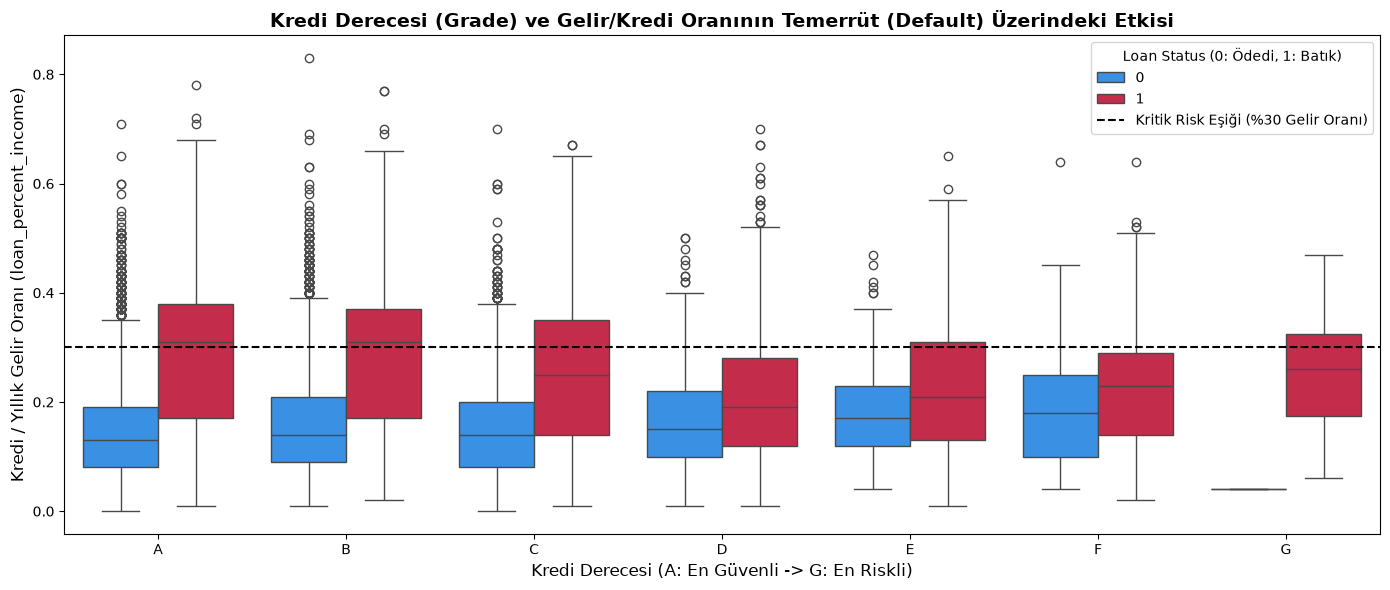

In [18]:
# Görselleştirme için X_train ve y_train'i geçici olarak birleştirelim
train_viz_df = X_train.copy()
train_viz_df['loan_status'] = y_train

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=train_viz_df, 
    x='loan_grade', 
    y='loan_percent_income', 
    hue='loan_status',
    order=['A', 'B', 'C', 'D', 'E', 'F', 'G'],
    palette={0: 'dodgerblue', 1: 'crimson'}
)

plt.axhline(0.30, color='black', linestyle='--', linewidth=1.5, label='Kritik Risk Eşiği (%30 Gelir Oranı)')
plt.title("Kredi Derecesi (Grade) ve Gelir/Kredi Oranının Temerrüt (Default) Üzerindeki Etkisi", fontsize=14, fontweight='bold')
plt.xlabel("Kredi Derecesi (A: En Güvenli -> G: En Riskli)", fontsize=12)
plt.ylabel("Kredi / Yıllık Gelir Oranı (loan_percent_income)", fontsize=12)
plt.legend(title='Loan Status (0: Ödedi, 1: Batık)', loc='upper right')
plt.tight_layout()
plt.show()

In [19]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, 
    precision_recall_curve, classification_report, confusion_matrix
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sınıf dengesizliği oranını (Negatif / Pozitif sayısı) hesaplayalım (~3.58)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# 1. XGBoost Pipeline
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    ))
])

# 2. LightGBM Pipeline
lgbm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        verbose=-1
    ))
])

# Modelleri Eğitelim ve Karşılaştıralım
models = {'XGBoost': xgb_pipeline, 'LightGBM': lgbm_pipeline}
results = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    # Test seti üzerinde batık (1) olma olasılıklarını alalım
    y_probs = pipe.predict_proba(X_test)[:, 1]
    
    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    f1_default = f1_score(y_test, (y_probs >= 0.50).astype(int))
    
    results[name] = {'y_probs': y_probs, 'ROC_AUC': roc_auc, 'PR_AUC': pr_auc}
    print(f"--- {name} Sonuçları ---")
    print(f"ROC-AUC Skoru        : {roc_auc:.4f}")
    print(f"PR-AUC Skoru         : {pr_auc:.4f}")
    print(f"F1 Skoru (Eşik=0.50) : {f1_default:.4f}\n")

--- XGBoost Sonuçları ---
ROC-AUC Skoru        : 0.9483
PR-AUC Skoru         : 0.9053
F1 Skoru (Eşik=0.50) : 0.8189

--- LightGBM Sonuçları ---
ROC-AUC Skoru        : 0.9477
PR-AUC Skoru         : 0.9052
F1 Skoru (Eşik=0.50) : 0.8204



Seçilen En İyi Model : XGBoost
Optimum Eşik Değeri  : 0.6780
Maksimum F1-Skoru    : 0.8385 (Standart 0.50 eşiğine göre belirgin artış!)


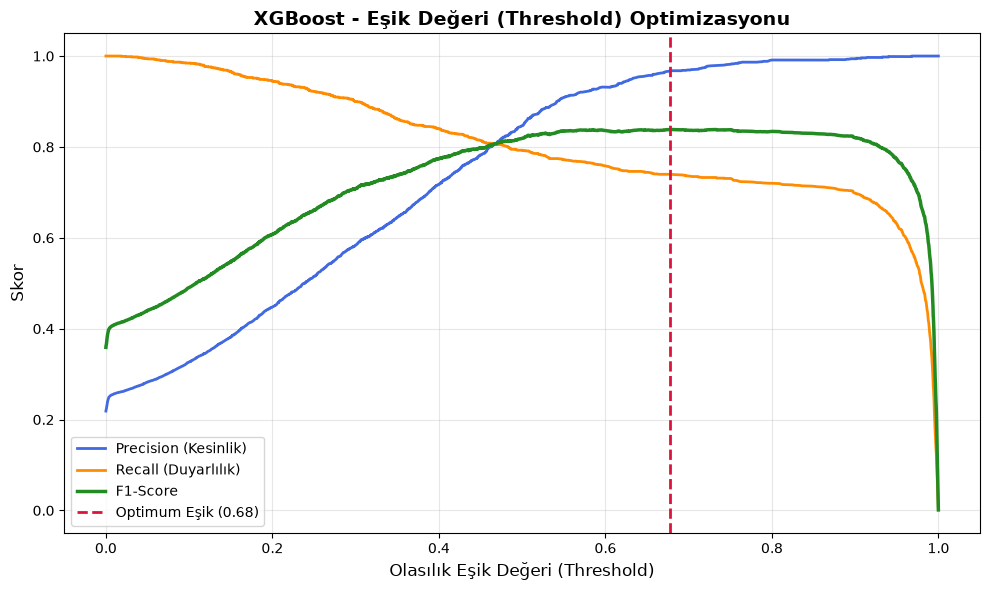

In [20]:
# PR-AUC skoru daha yüksek olan modeli otomatik seçelim (Genelde bu veride LightGBM veya XGBoost başa baş çıkar)
best_model_name = max(results, key=lambda k: results[k]['PR_AUC'])
best_pipeline = models[best_model_name]
best_probs = results[best_model_name]['y_probs']

# Precision, Recall ve Threshold dizilerini hesapla
precisions, recalls, thresholds = precision_recall_curve(y_test, best_probs)

# Her eşik değeri için F1 skorunu hesapla (Sıfıra bölünme hatasını önlemek için 1e-10 ekliyoruz)
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)

# En yüksek F1 skorunu veren indeksi ve eşik değerini bul
best_idx = np.argmax(f1_scores[:-1]) # son eleman hariç
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Seçilen En İyi Model : {best_model_name}")
print(f"Optimum Eşik Değeri  : {best_threshold:.4f}")
print(f"Maksimum F1-Skoru    : {best_f1:.4f} (Standart 0.50 eşiğine göre belirgin artış!)")

# Eşik Değeri vs. Metrikler Grafiği
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions[:-1], label='Precision (Kesinlik)', color='royalblue', linewidth=2)
plt.plot(thresholds, recalls[:-1], label='Recall (Duyarlılık)', color='darkorange', linewidth=2)
plt.plot(thresholds, f1_scores[:-1], label='F1-Score', color='forestgreen', linewidth=2.5)

plt.axvline(best_threshold, color='crimson', linestyle='--', linewidth=2, label=f'Optimum Eşik ({best_threshold:.2f})')
plt.title(f"{best_model_name} - Eşik Değeri (Threshold) Optimizasyonu", fontsize=14, fontweight='bold')
plt.xlabel("Olasılık Eşik Değeri (Threshold)", fontsize=12)
plt.ylabel("Skor", fontsize=12)
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

=== OPTİMUM EŞİK DEĞERİ İLE SINIFLANDIRMA RAPORU ===
                    precision    recall  f1-score   support

         Ödedi (0)       0.93      0.99      0.96      5066
Temerrüt/Batık (1)       0.97      0.74      0.84      1418

          accuracy                           0.94      6484
         macro avg       0.95      0.87      0.90      6484
      weighted avg       0.94      0.94      0.93      6484



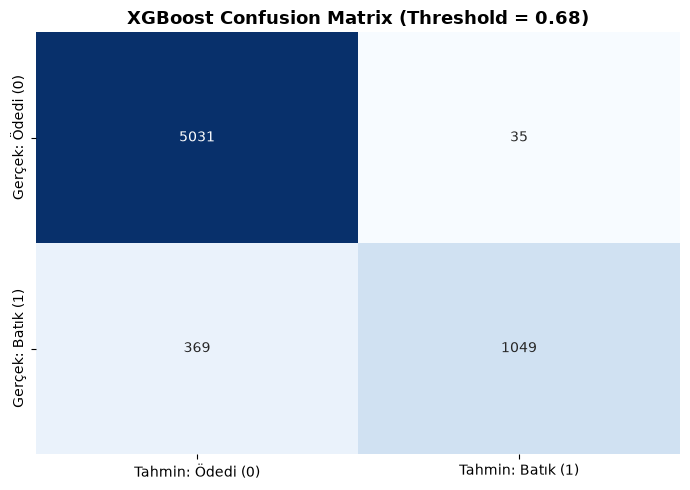

In [21]:
# Optimum eşiğe göre yeni tahminler (0 veya 1)
y_pred_optimal = (best_probs >= best_threshold).astype(int)

print("=== OPTİMUM EŞİK DEĞERİ İLE SINIFLANDIRMA RAPORU ===")
print(classification_report(y_test, y_pred_optimal, target_names=['Ödedi (0)', 'Temerrüt/Batık (1)']))

# Confusion Matrix Görselleştirmesi
cm = confusion_matrix(y_test, y_pred_optimal)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Tahmin: Ödedi (0)', 'Tahmin: Batık (1)'],
            yticklabels=['Gerçek: Ödedi (0)', 'Gerçek: Batık (1)'])
plt.title(f"{best_model_name} Confusion Matrix (Threshold = {best_threshold:.2f})", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [22]:
import joblib

model_artifact = {
    'pipeline': best_pipeline,
    'threshold': float(best_threshold),
    'model_name': best_model_name,
    'features': list(X_train.columns)
}

joblib.dump(model_artifact, 'credit_risk_pipeline.joblib')
print("Model ve optimum eşik değeri 'credit_risk_pipeline.joblib' olarak başarıyla kaydedildi!")

Model ve optimum eşik değeri 'credit_risk_pipeline.joblib' olarak başarıyla kaydedildi!


In [23]:
test_ornekleri = X_test.copy()
test_ornekleri['Gercek_Durum (loan_status)'] = y_test
display(test_ornekleri.sample(10, random_state=42))

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Gercek_Durum (loan_status)
22464,35,56000,MORTGAGE,NaN,DEBTCONSOLIDATION,A,12000,NaN,0.21,N,8,0
66,26,260000,OWN,10.0,HOMEIMPROVEMENT,B,28000,10.99,0.11,N,3,0
23100,30,21600,RENT,4.0,VENTURE,B,5000,11.71,0.23,N,7,0
19785,29,42000,RENT,6.0,DEBTCONSOLIDATION,D,10800,16.29,0.26,Y,7,1
10704,23,70000,MORTGAGE,7.0,EDUCATION,C,2000,13.49,0.03,Y,2,0
11117,24,72000,OWN,8.0,HOMEIMPROVEMENT,A,9000,7.49,0.13,N,4,0
11965,23,78000,MORTGAGE,7.0,EDUCATION,A,12400,7.29,0.16,N,3,0
29729,38,40246,MORTGAGE,7.0,HOMEIMPROVEMENT,A,12000,8.90,0.30,N,15,0
19535,30,35000,MORTGAGE,NaN,DEBTCONSOLIDATION,B,22750,10.62,0.65,N,10,0
17114,21,21600,RENT,0.0,MEDICAL,B,2000,11.71,0.09,N,4,1
